# Clase 4: manejo de datos y herramientas de análisis

**Diplomado en IA Generativa · CENIA**
Docente: Francesca Lucchini

---

## Caso: inspección de planchas de acero

Una planta siderúrgica quiere clasificar automáticamente **7 tipos de falla** en planchas de acero
a partir de 27 features geométricas y de luminosidad extraídas de imágenes.
Usaremos el dataset **Steel Plates Faults** (UCI Machine Learning Repository, licencia CC BY 4.0). [Link](https://www.kaggle.com/datasets/noepinefrin/steel-plates-faults-dataset)

Es un dataset pequeño (1.941 ejemplos), y tiene
**desbalance de clases** real, para poder practicar aumentación de datos con SMOTE.

## Objetivos

1. Cargar el dataset y hacer un EDA rápido
2. Separar en train / validation / test
3. Aumentar los datos de train con **SMOTE**
4. Construir **a mano** nuestras clases `Dataset` y `DataLoader`
5. Entrenar, observando curvas de loss para train y validation, usando **early stopping**
6. Evaluar matriz de confusión, precision, recall y F1

**Todo el procesamiento lo hacemos con PyTorch:** el split, la normalización, SMOTE, la visualización
con PCA y las métricas. Así se ve qué hay detrás de cada herramienta. `pandas` se usa para cargar y explorar los datos (EDA),
y `matplotlib` para los gráficos.

> Esta práctica corre bien con CPU: no necesitas GPU.

## 0. Setup


In [1]:
# Paquete para importar fácilmente conjuntos de datos desde el Repositorio de
# Aprendizaje Automático de UC Irvine
!pip install -q ucimlrepo

In [2]:
import copy
import math

import matplotlib.pyplot as plt
import pandas as pd
import torch
import torch.nn as nn
from IPython.display import display
from torch.utils.data import DataLoader, Dataset, Subset

# Establece la semilla para generar números aleatorios en todos los dispositivos.
# Define el punto de partida para el generador de números aleatorios de PyTorch
# (Inicialización de pesos, mezcla de datos, aumentación de datos, capas estocásticas, etc.)
SEED = 42
torch.manual_seed(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Usando: {device}")

Usando: cpu


## 1. Cargar el dataset
El dataset trae las 7 clases como columnas one-hot (una columna por tipo de falla, con un 1 en la falla correspondiente). Las convertimos a una sola label con valores de 0 a 6 y pasamos todo a tensores.

In [3]:
def load_steel_faults():
    """Descarga Steel Plates Faults desde UCI (id=198). Si UCI no responde, usa una copia pública en CSV.

    Devuelve dos DataFrames: las 27 features y las 7 columnas one-hot del target.
    """
    # try / except: si la descarga desde UCI falla (sin internet, servidor caído),
    # el notebook no se cae: pasa al bloque except y prueba la copia alternativa
    try:
        from ucimlrepo import fetch_ucirepo

        repo = fetch_ucirepo(id=198)
        features, targets = repo.data.features, repo.data.targets
    except Exception as err:
        print(f"No se pudo descargar desde UCI ({err}). Probando copia alternativa...")
        df = pd.read_csv("http://apmonitor.com/pds/uploads/Main/steel.txt")
        # En la copia CSV las 7 últimas columnas son el target one-hot
        features, targets = df.iloc[:, :-7], df.iloc[:, -7:]
    # reset_index deja los índices de fila en 0, 1, 2... para que features y targets calcen fila a fila
    return features.reset_index(drop=True), targets.reset_index(drop=True)


features_df, targets_df = load_steel_faults()

In [4]:
# 5 filas al azar de las features
features_df.sample(5)

,X_Minimum,X_Maximum,Y_Minimum,Y_Maximum,Pixels_Areas,X_Perimeter,Y_Perimeter,Sum_of_Luminosity,Maximum_of_Luminosity,Length_of_Conveyer,...,Edges_X_Index,Edges_Y_Index,Outside_Global_Index,LogOfAreas,Log_X_Index,Log_Y_Index,Orientation_Index,Luminosity_Index,SigmoidOfAreas,Minimum_of_Luminosity
1322,963,974,657468,657502,201,38,35,26197,141,1372,...,0.2895,0.9714,1.0,2.3032,1.0414,1.5315,0.6765,0.0182,0.6173,123
679,41,218,2698232,2698294,6327,275,148,660291,126,1358,...,0.6436,0.4189,0.0,3.8012,2.2480,1.7924,-0.6497,-0.1847,1.0000,40
1512,1580,1590,3160372,3160387,87,20,15,9275,124,1690,...,0.5000,1.0000,1.0,1.9395,1.0000,1.1761,0.3333,-0.1671,0.2660,99
1485,237,252,109868,109903,301,42,35,29002,103,1692,...,0.3571,1.0000,1.0,2.4786,1.1761,1.5441,0.5714,-0.2473,0.8153,89
359,1212,1220,198764,198776,74,12,12,13025,188,1387,...,0.6667,1.0000,1.0,1.8692,0.9031,1.0792,0.3333,0.3751,0.2018,163


In [5]:
# 5 filas al azar del target: cada fila tiene un 1 en la columna de su tipo de falla
targets_df.sample(5)

,Pastry,Z_Scratch,K_Scratch,Stains,Dirtiness,Bumps,Other_Faults
953,0,0,0,0,0,1,0
256,0,1,0,0,0,0,0
1048,0,0,0,0,0,1,0
1894,0,0,0,0,0,0,1
767,0,0,0,1,0,0,0


Recordatorio de conceptos:
- **Features**: las 27 columnas que describen cada falla (posición, área, perímetro, luminosidad...).
- **Target / label / ground truth**: el tipo de falla que queremos predecir.

In [6]:
# De pandas a tensores, armando el dataset
# Features
X_all = torch.tensor(features_df.to_numpy(), dtype=torch.float32)
# Labels
targets_onehot = torch.tensor(targets_df.to_numpy(), dtype=torch.long)
y_all = targets_onehot.argmax(dim=1)  # one-hot -> índice de clase

# Nombres de las clases
feature_names = list(features_df.columns)
class_names = list(targets_df.columns)
num_features, num_classes = X_all.shape[1], len(class_names)

# Tamaños
print(f"X_all: {tuple(X_all.shape)} · y_all: {tuple(y_all.shape)} · clases: {num_classes}")
print("Clases:", class_names)


X_all: (1941, 27) · y_all: (1941,) · clases: 7
Clases: ['Pastry', 'Z_Scratch', 'K_Scratch', 'Stains', 'Dirtiness', 'Bumps', 'Other_Faults']


## 2. EDA rápido

Antes de entrenar, miramos los datos: ¿cómo se distribuyen las features? ¿Cuántos ejemplos hay de cada clase? ¿Hay valores faltantes o
duplicados? ¿Los rangos de las features son comparables?

In [7]:
# isnan marca con True los valores faltantes (NaN); al sumarlos obtenemos cuántos hay
print("Valores faltantes:", int(torch.isnan(X_all).sum()))
# unique(dim=0) deja solo las filas distintas: la diferencia con el total son las filas repetidas
print("Filas duplicadas:", len(X_all) - len(torch.unique(X_all, dim=0)))

# describe() calcula count, mean, std, min, 25%, 50% (mediana), 75% y max.
# Solo incluye columnas numéricas; .T la transpone para tener una fila por feature
eda = features_df.describe().T
# Agregamos el tipo de dato y la cantidad de valores distintos
# (pocos valores únicos = feature binaria o categórica, aunque esté guardada como número)
eda.insert(0, "tipo", features_df.dtypes.astype(str))
eda.insert(1, "valores únicos", features_df.nunique())

# Si hubiera columnas de texto o categóricas, se resumen aparte
if not features_df.select_dtypes(exclude="number").empty:
    display(features_df.describe(exclude="number").T)

# Rangos muy distintos entre features: motivo para normalizar.
# Si mean es mucho mayor que 50% (la mediana), la feature tiene cola larga (outliers hacia arriba).
# style.format muestra los números con decimales y separador de miles (sin notación científica)
stat_cols = ["mean", "std", "min", "25%", "50%", "75%", "max"]
eda.style.format("{:,.2f}", subset=stat_cols).format("{:,.0f}", subset=["count"])

Valores faltantes: 0
Filas duplicadas: 0


,tipo,valores únicos,count,mean,std,min,25%,50%,75%,max
X_Minimum,int64,962,"1,941",571.14,520.69,0.00,51.00,435.00,"1,053.00","1,705.00"
X_Maximum,int64,994,"1,941",617.96,497.63,4.00,192.00,467.00,"1,072.00","1,713.00"
Y_Minimum,int64,1939,"1,941","1,650,684.87","1,774,578.41","6,712.00","471,253.00","1,204,128.00","2,183,073.00","12,987,661.00"
Y_Maximum,int64,1940,"1,941","1,650,738.71","1,774,590.09","6,724.00","471,281.00","1,204,136.00","2,183,084.00","12,987,692.00"
Pixels_Areas,int64,920,"1,941","1,893.88","5,168.46",2.00,84.00,174.00,822.00,"152,655.00"
X_Perimeter,int64,399,"1,941",111.86,301.21,2.00,15.00,26.00,84.00,"10,449.00"
Y_Perimeter,int64,317,"1,941",82.97,426.48,1.00,13.00,25.00,83.00,"18,152.00"
Sum_of_Luminosity,int64,1909,"1,941","206,312.15","512,293.59",250.00,"9,522.00","19,202.00","83,011.00","11,591,414.00"
Maximum_of_Luminosity,int64,100,"1,941",130.19,18.69,37.00,124.00,127.00,140.00,253.00
Length_of_Conveyer,int64,84,"1,941","1,459.16",144.58,"1,227.00","1,358.00","1,364.00","1,650.00","1,794.00"


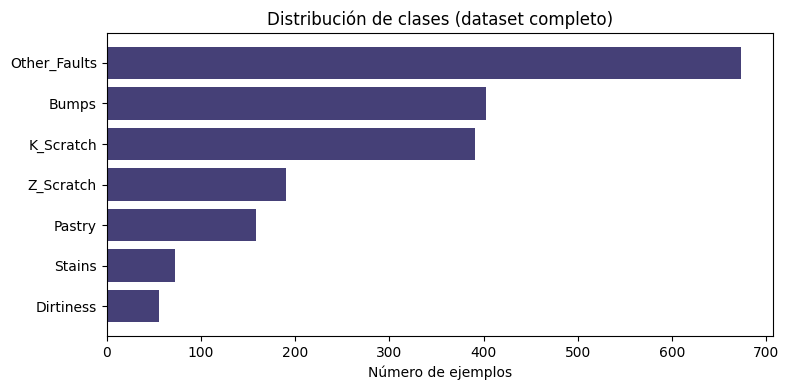

Other_Faults    673
Bumps           402
K_Scratch       391
Z_Scratch       190
Pastry          158
Stains           72
Dirtiness        55

Proporción clase mayoritaria vs minoritaria: 12.2x


In [8]:
# Cuenta la frecuencia de cada valor en un tensor unidimensional de enteros no negativos
counts = torch.bincount(y_all, minlength=num_classes)
# argsort entrega los índices que ordenan las clases de menor a mayor cantidad
order = counts.argsort()

# Gráfico de distribución de clases
plt.figure(figsize=(8, 4))
plt.barh([class_names[i] for i in order], counts[order].numpy(), color="#454077")
plt.title("Distribución de clases (dataset completo)")
plt.xlabel("Número de ejemplos")
plt.tight_layout()
plt.show()

# Cantidad por clase (flip invierte el orden: de mayor a menor)
for i in order.flip(0):
    print(f"{class_names[i]:<14}{counts[i].item():>5}")

# Desbalance de clases
print(f"\nProporción clase mayoritaria vs minoritaria: {
    (counts.max() / counts.min()).item():.1f}x")

In [9]:
# Si un modelo predijera SIEMPRE la clase mayoritaria, ¿qué accuracy tendría?
baseline_acc = counts.max() / counts.sum()
print(f"Accuracy de predecir siempre '{class_names[counts.argmax()]}': {baseline_acc.item():.1%}")

Accuracy de predecir siempre 'Other_Faults': 34.7%


(uf, qué suerte)

**Para comentar:** la clase más chica tiene más de 10 veces menos ejemplos que la más grande, y un
modelo trivial ya logra cerca de 35 % de accuracy. Por eso, en la evaluación no basta con accuracy:
miraremos precision, recall y F1 por clase.

En la tabla de features, compara **mean (promedio)** y **50% (la mediana)**: cuando mean es mucho mayor, la feature tiene cola larga u outliers (lo retomamos en la normalización). Y mira los **valores únicos**: una feature con 2 o 3 valores es binaria o categórica, aunque esté guardada como número.

## 3. Split train / validation / test

- **Train** (70 %): el modelo aprende de estos datos.
- **Validation** (15 %), también llamado *dev set*: monitoreamos el training y tomamos decisiones
  (hyperparameters, cuándo parar).
- **Test** (15 %): se usa **una sola vez** al final, para reportar métricas en las que confiamos.

Hacemos un split **estratificado** a mano: separamos cada clase por su cuenta, así los tres sets
mantienen la misma proporción de clases. Con clases desbalanceadas esto es importante: **sin estratificar,
una clase con 55 ejemplos podría quedar casi ausente del test.**

In [10]:
def stratified_split(labels, val_frac=0.15, test_frac=0.15, seed=SEED):
    """Devuelve índices de train, validation y test manteniendo la proporción de
    cada clase."""
    # Generación de números pseudo-aleatorios
    generator = torch.Generator().manual_seed(seed)
    train_idx, val_idx, test_idx = [], [], []
    for c in labels.unique():
        # Obtener sólo ejemplos de la clase c
        idx = (labels == c).nonzero(as_tuple=True)[0]
        # Desordenamos dentro de la clase
        idx = idx[torch.randperm(len(idx), generator=generator)]
        # Cantidad de datos para val y test
        n_test = round(len(idx) * test_frac)
        n_val = round(len(idx) * val_frac)
        # Sacamos un pedazo para test y val de los datos desordenados
        test_idx.append(idx[:n_test])
        val_idx.append(idx[n_test : n_test + n_val])
        # El resto queda para train
        train_idx.append(idx[n_test + n_val :])

    # Retornamos los índices seleccionados
    return torch.cat(train_idx), torch.cat(val_idx), torch.cat(test_idx)

train_idx, val_idx, test_idx = stratified_split(y_all)
# Usando los índices armamos los splits
X_train, y_train = X_all[train_idx], y_all[train_idx]
X_val, y_val = X_all[val_idx], y_all[val_idx]
X_test, y_test = X_all[test_idx], y_all[test_idx]

# Resumen de lo armado
split_counts = pd.DataFrame(
    {
        "train": torch.bincount(y_train, minlength=num_classes).numpy(),
        "validation": torch.bincount(y_val, minlength=num_classes).numpy(),
        "test": torch.bincount(y_test, minlength=num_classes).numpy(),
    },
    index=class_names,
)
print(f"Tamaños -> train: {len(X_train)} · validation: {len(X_val)} · test: {len(X_test)}")
split_counts

Tamaños -> train: 1359 · validation: 291 · test: 291


,train,validation,test
Pastry,110,24,24
Z_Scratch,134,28,28
K_Scratch,273,59,59
Stains,50,11,11
Dirtiness,39,8,8
Bumps,282,60,60
Other_Faults,471,101,101


In [11]:
# Chequeo de data duplicada: ¿hay filas idénticas entre train y validation/test?
def count_duplicates(X_a, X_b):
    """Cuántas filas de X_a aparecen tal cual en X_b (comparación fila contra fila).

    Truco de broadcasting: X_a[:, None, :] tiene forma (n_a, 1, features) y
    X_b[None, :, :] tiene forma (1, n_b, features). Al compararlos, PyTorch los
    "estira" a (n_a, n_b, features) y compara todas las filas contra todas.
    - .all(dim=2): la fila es idéntica solo si TODAS sus features coinciden
    - .any(dim=1): la fila de X_a está repetida si coincide con ALGUNA fila de X_b
    """
    return int((X_a[:, None, :] == X_b[None, :, :]).all(dim=2).any(dim=1).sum())


print(
    f"Duplicados train-validation: {count_duplicates(X_val, X_train)} · train-test: {count_duplicates(X_test, X_train)}"
)

Duplicados train-validation: 0 · train-test: 0


## 4. Normalización de datos

Normalizamos cada feature para que quede con media 0 y desviación estándar 1, como vimos en la clase 1:
$x' = (x - \mu) / \sigma$.

**Clave:** $\mu$ y $\sigma$ se calculan **solo con train**. Validation y test se transforman con esos
mismos valores, porque en producción no conoceremos los datos futuros (Data Leakage).

In [13]:
# μ y σ se calculan SOLO con train (dim=0: una media y una desviación por feature)
mu = X_train.mean(dim=0)
sigma = X_train.std(dim=0).clamp_min(1e-8)  # evitamos dividir por cero


def standardize(X):
    """Normaliza con la media y desviación de train: x' = (x - μ) / σ."""
    return (X - mu) / sigma


# Los tres splits se transforman con los MISMOS μ y σ de train
X_train_s, X_val_s, X_test_s = standardize(X_train), standardize(X_val), standardize(X_test)

print(f"Train -> media: {X_train_s.mean():.3f} · std: {X_train_s.std():.3f}")
print(f"Val   -> media: {X_val_s.mean():.3f} · std: {X_val_s.std():.3f}")
print(f"Test  -> media: {X_test_s.mean():.3f} · std: {X_test_s.std():.3f}\n")

# Validation no queda exactamente en media 0 y std 1 porque usamos μ y σ de train.
# Si la std se aleja mucho de 1, revisemos qué features la causan:
val_std = X_val_s.std(dim=0)
# argsort(descending=True) ordena las features de mayor a menor std;
# luego sorted(..., key=...) las reordena alfabéticamente por nombre para leerlas más fácil
top_val_indices = val_std.argsort(descending=True)[:27].tolist()
top_val_features = sorted(top_val_indices, key=lambda i: feature_names[i])

for i in top_val_features:
    print(f"  {feature_names[i]:<22} std en validation: {val_std[i]:.2f}")

print()
# Mismo análisis para test
test_std = X_test_s.std(dim=0)
top_test_indices = test_std.argsort(descending=True)[:27].tolist()
top_test_features = sorted(top_test_indices, key=lambda i: feature_names[i])

for i in top_test_features:
    print(f"  {feature_names[i]:<22} std en test: {test_std[i]:.2f}")

Train -> media: -0.000 · std: 1.000
Val   -> media: 0.046 · std: 2.148
Test  -> media: -0.010 · std: 0.937

  Edges_Index            std en validation: 0.97
  Edges_X_Index          std en validation: 0.99
  Edges_Y_Index          std en validation: 0.99
  Empty_Index            std en validation: 1.05
  Length_of_Conveyer     std en validation: 0.96
  LogOfAreas             std en validation: 1.01
  Log_X_Index            std en validation: 0.98
  Log_Y_Index            std en validation: 1.05
  Luminosity_Index       std en validation: 0.92
  Maximum_of_Luminosity  std en validation: 0.88
  Minimum_of_Luminosity  std en validation: 1.01
  Orientation_Index      std en validation: 0.98
  Outside_Global_Index   std en validation: 1.00
  Outside_X_Index        std en validation: 0.90
  Pixels_Areas           std en validation: 2.47
  SigmoidOfAreas         std en validation: 1.01
  Square_Index           std en validation: 1.00
  Steel_Plate_Thickness  std en validation: 1.05
  Sum_of_L

In [14]:
# (Opcional) Feature engineering contra outliers: comparamos transformaciones antes de normalizar.
# - log: comprime las colas largas (áreas, perímetros, luminosidad).
# - clipping: "capea" cada feature al rango p1-p99 de train (los límites salen SOLO de train).

# Features con "cola larga": siempre positivas y con valores máximos muy grandes
heavy_tail = [i for i in range(num_features) if X_train[:, i].min() >= 0 and X_train[:, i].max() > 1000]


def log_transform(X):
    """Aplica log(1 + x) solo a las features de cola larga."""
    X = X.clone()  # copia, para no modificar el tensor original
    X[:, heavy_tail] = torch.log1p(X[:, heavy_tail])
    return X


def clip_to_train(tr, va, q=0.01):
    """Recorta train y validation a los percentiles q y 1-q calculados con train.

    torch.quantile da el percentil por feature; maximum/minimum fijan los
    valores bajo el límite inferior (lo) y sobre el límite superior (hi).
    """
    lo, hi = torch.quantile(tr, q, dim=0), torch.quantile(tr, 1 - q, dim=0)
    return torch.minimum(torch.maximum(tr, lo), hi), torch.minimum(torch.maximum(va, lo), hi)


def val_std(tr, va):
    """Normaliza validation con μ y σ de train y devuelve la std global (ideal: cerca de 1)."""
    m, s = tr.mean(dim=0), tr.std(dim=0).clamp_min(1e-8)
    return ((va - m) / s).std().item()


tr_l, va_l = log_transform(X_train), log_transform(X_val)
print("std de validation después de normalizar (ideal: cerca de 1)")
print(f"  sin transformar:  {val_std(X_train, X_val):.2f}")
print(f"  log:              {val_std(tr_l, va_l):.2f}")
# El * "desempaqueta" la tupla (train, val) que devuelve clip_to_train como dos argumentos
print(f"  clipping p1-p99:  {val_std(*clip_to_train(X_train, X_val)):.2f}")
print(f"  log + clipping:   {val_std(*clip_to_train(tr_l, va_l)):.2f}")
# Ojo: esta celda es ilustrativa; no modifica el dataset

std de validation después de normalizar (ideal: cerca de 1)
  sin transformar:  2.15
  log:              1.99
  clipping p1-p99:  1.00
  log + clipping:   0.99


## 5. Data augmentation con SMOTE, solo sobre train

**SMOTE** (*Synthetic Minority Over-sampling Technique*) crea ejemplos sintéticos de las clases
minoritarias:

1. Toma un ejemplo $x_i$ de la clase minoritaria.
2. Busca uno de sus $k$ vecinos más cercanos $x_{vecino}$ **de la misma clase**.
3. Genera un punto nuevo en el segmento entre ambos:
   $x_{nuevo} = x_i + \lambda \cdot (x_{vecino} - x_i)$, con $\lambda$ aleatorio entre 0 y 1.

Primero generamos **un solo punto** paso a paso, y después lo implementamos para todas las clases.



> Fuente: [Creating SMOTE Oversampling from Scratch](https://towardsdatascience.com/creating-smote-oversampling-from-scratch-64af1712a3be/) 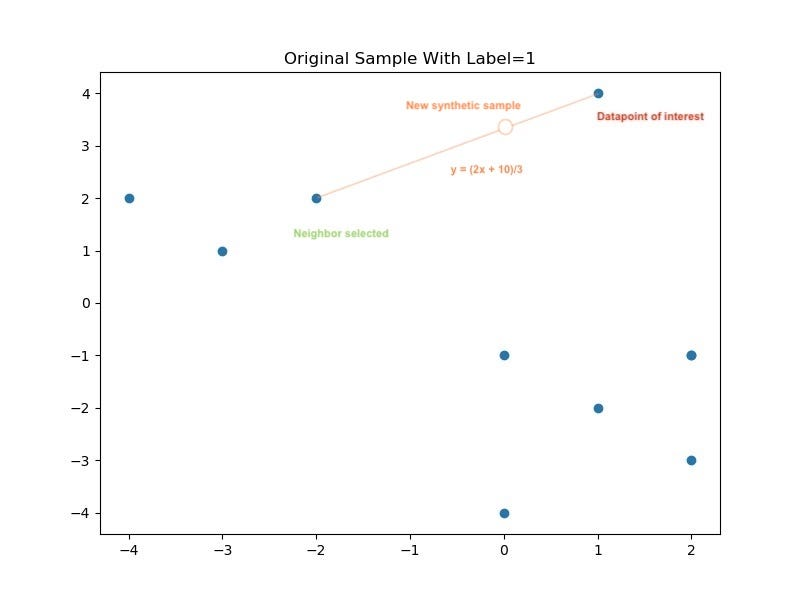

In [15]:
# Un punto sintético, paso a paso, para la clase menos representada
minority = int(torch.bincount(y_train).argmin())
X_min = X_train_s[y_train == minority]

# Distancia euclidiana de x_i a todos los de su clase
dist = torch.cdist(X_min[:1], X_min)[0]
# Caso especial: x_i no debe ser vecino de sí mismo, por lo que se considera inf
dist[0] = float("inf")
# Encontramos los 5 vecinos más cercanos (largest=False: las 5 distancias más pequeñas)
neighbors = dist.topk(5, largest=False).indices

x_i = X_min[0]
# Elegimos el más lejano de los 5 vecinos, para que la interpolación se note.
# Pero podría ser al azar también.
x_vecino = X_min[neighbors[-1]]
# Ponderación de en qué lugar generar el nuevo punto entre los dos observados
lam = torch.rand(1)
x_nuevo = x_i + lam * (x_vecino - x_i)

print(f"Clase minoritaria: {class_names[minority]} ({len(X_min)} ejemplos en train)")
print(f"lambda = {lam.item():.2f}")
# Las 4 features donde más difieren
show = (x_vecino - x_i).abs().topk(4).indices
print("Features donde x_i y el vecino más difieren:", [feature_names[i] for i in show])
print("  x_i:     ", x_i[show].numpy().round(2))
print("  vecino:  ", x_vecino[show].numpy().round(2))
print("  x_nuevo: ", x_nuevo[show].numpy().round(2))

Clase minoritaria: Dirtiness (39 ejemplos en train)
lambda = 0.88
Features donde x_i y el vecino más difieren: ['Edges_X_Index', 'Log_Y_Index', 'SigmoidOfAreas', 'LogOfAreas']
  x_i:      [-1.55  0.4  -0.42 -0.31]
  vecino:   [-0.76 -0.32 -1.08 -0.87]
  x_nuevo:  [-0.85 -0.23 -1.   -0.8 ]


In [16]:
def smote(X, y, k=5, seed=SEED):
    """SMOTE en PyTorch: iguala todas las clases al tamaño de la mayoritaria.

    Para cada clase con menos ejemplos que la mayoritaria, genera los puntos que le faltan
    interpolando entre ejemplos reales de esa misma clase y sus k vecinos más cercanos.
    Devuelve los datos originales seguidos de los sintéticos (al final).
    """
    # Generador propio con semilla: SMOTE da el mismo resultado cada vez que se ejecuta
    generator = torch.Generator().manual_seed(seed)
    counts = torch.bincount(y)
    # Partimos con los datos originales; los sintéticos se agregan después
    X_parts, y_parts = [X], [y]

    for c in range(len(counts)):
        # Cuántos ejemplos le faltan a la clase c para igualar a la mayoritaria
        n_new = int(counts.max() - counts[c])
        if n_new == 0:
            continue  # es la clase mayoritaria: no necesita aumentación
        X_c = X[y == c]
        # Si la clase tiene muy pocos ejemplos, no podemos pedir más vecinos que los que existen
        k_c = min(k, len(X_c) - 1)

        # 1. Vecinos más cercanos dentro de la misma clase
        dist = torch.cdist(X_c, X_c)  # matriz (n_c, n_c) con todas las distancias
        dist.fill_diagonal_(float("inf"))  # un punto no es vecino de sí mismo
        neighbors = dist.topk(k_c, largest=False).indices  # (n_c, k)

        # 2. Elegimos al azar un punto base y uno de sus vecinos
        base = torch.randint(len(X_c), (n_new,), generator=generator)
        # Para cada punto base, una columna al azar de su fila en `neighbors`
        neighbor = neighbors[base, torch.randint(k_c, (n_new,), generator=generator)]

        # 3. Interpolamos: x_i + lambda * (x_vecino - x_i)
        # lam tiene forma (n_new, 1) para que el mismo lambda se aplique a todas las features del punto
        lam = torch.rand(n_new, 1, generator=generator)
        X_parts.append(X_c[base] + lam * (X_c[neighbor] - X_c[base]))
        y_parts.append(torch.full((n_new,), c, dtype=y.dtype))  # label c para todos los sintéticos

    return torch.cat(X_parts), torch.cat(y_parts)


# SMOTE se aplica SOLO sobre train, ya normalizado
X_train_sm, y_train_sm = smote(X_train_s, y_train)

# Conteo por clase antes y después de SMOTE
comparison = pd.DataFrame(
    {
        "train original": torch.bincount(y_train, minlength=num_classes).numpy(),
        "train + SMOTE": torch.bincount(y_train_sm, minlength=num_classes).numpy(),
    },
    index=class_names,
)
print(f"Train: {len(X_train_s)} -> {len(X_train_sm)} ejemplos")
comparison

Train: 1359 -> 3297 ejemplos


,train original,train + SMOTE
Pastry,110,471
Z_Scratch,134,471
K_Scratch,273,471
Stains,50,471
Dirtiness,39,471
Bumps,282,471
Other_Faults,471,471


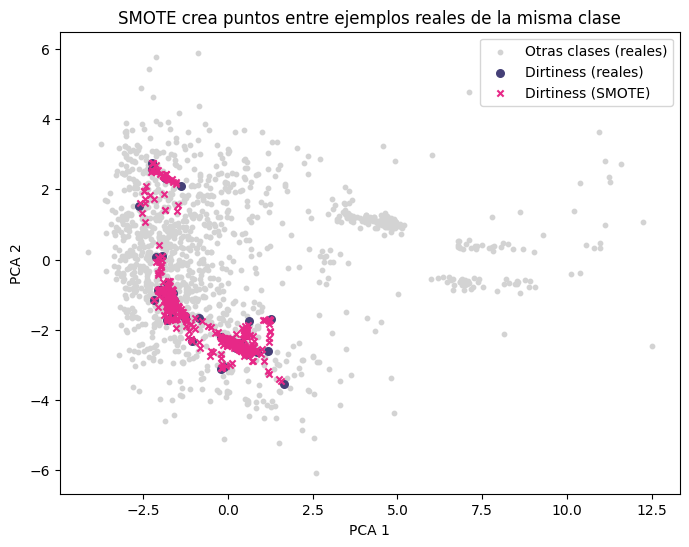

In [17]:
# Visualización en 2D con PCA: reales vs. sintéticos
center = X_train_s.mean(dim=0)
# SVD de los datos centrados: las filas de Vh son las direcciones principales
_, _, Vh = torch.linalg.svd(X_train_s - center, full_matrices=False)
# Las 2 direcciones de mayor varianza
components = Vh[:2].T

def project(X, components):
  """Proyecta X sobre los componentes principales (PCA).

    Resta `center` (la media de los datos de entrenamiento) y luego
    multiplica por `components` con `@`, el operador de multiplicación
    de matrices. `components` es una matriz (d, k) cuyas columnas son
    las direcciones principales, así que el resultado expresa cada
    punto en k coordenadas en vez de d."""
  return (X - center) @ components


n_original = len(X_train_s)
# Indica que los valores al final son sintéticos
is_synthetic = torch.arange(len(X_train_sm)) >= n_original

# Proyección PCA para reales y sintéticos
real_2d = project(X_train_s, components).numpy()
synth_2d = project(X_train_sm[is_synthetic & (y_train_sm == minority)], components).numpy()
# Máscara de clase menos representada
mask_min = (y_train == minority).numpy()

plt.figure(figsize=(8, 6))
plt.scatter(real_2d[:, 0], real_2d[:, 1], c="lightgray", s=10, label="Otras clases (reales)")
plt.scatter(real_2d[mask_min, 0], real_2d[mask_min, 1], c="#454077", s=30, label=f"{class_names[minority]} (reales)")
plt.scatter(synth_2d[:, 0], synth_2d[:, 1], c="#e72887", s=20, marker="x", label=f"{class_names[minority]} (SMOTE)")
plt.title("SMOTE crea puntos entre ejemplos reales de la misma clase")
plt.xlabel("PCA 1")
plt.ylabel("PCA 2")
plt.legend()
plt.show()

**Importante:**
- SMOTE se aplica **después del split y solo sobre train**. Validation y test deben reflejar la
  distribución real; si los aumentamos, las métricas mienten.
- SMOTE funciona sobre vectores numéricos (datos tabulares). Para imágenes o texto usamos otras
  técnicas de augmentation (rotaciones, back-translation, etc.).
- En proyectos reales se suele usar la librería `imbalanced-learn` (`SMOTE().fit_resample(X, y)`), que
  implementa esta misma idea.

## 6. Nuestra clase `Dataset`

Un `Dataset` de PyTorch es una clase que responde dos preguntas:
- `__len__`: ¿cuántos ejemplos hay?
- `__getitem__(idx)`: ¿cuál es el ejemplo número `idx`? (devuelve features y label)

[Pytorch Docs: "Datasets & DataLoaders"](https://docs.pytorch.org/tutorials/beginner/basics/data_tutorial.html)

In [18]:
class SteelFaultsDataset(Dataset):
    """Dataset de PyTorch para las planchas de acero: guarda features y labels como tensores."""

    def __init__(self, features, labels):
        # float para las features (entrada de la red) y long (enteros) para las labels,
        # que es el tipo que espera CrossEntropyLoss
        self.features = features.float()
        self.labels = labels.long()

    def __len__(self):
        # ¿Cuántos ejemplos hay?
        return len(self.labels)

    def __getitem__(self, idx):
        # ¿Cuál es el ejemplo número idx? Devuelve la tupla (features, label)
        return self.features[idx], self.labels[idx]

# Usamos la clase para crear instancias con nuestros datos
train_ds = SteelFaultsDataset(X_train_s, y_train)
train_sm_ds = SteelFaultsDataset(X_train_sm, y_train_sm)
val_ds = SteelFaultsDataset(X_val_s, y_val)
test_ds = SteelFaultsDataset(X_test_s, y_test)

# Ejemplo de cómo explorar la clase
x0, y0 = train_ds[0]
print(f"len(train_ds) = {len(train_ds)}")
print(f"len(train_sm_ds) = {len(train_sm_ds)}")
print(f"Ejemplo 0 -> features: {tuple(x0.shape)} · label: {y0.item()} ({class_names[y0.item()]})")

# Funciona como una lista
print(f"train_ds[0] = {train_ds[0]}")
print(f"train_ds[20] = {train_ds[20]}")


len(train_ds) = 1359
len(train_sm_ds) = 3297
Ejemplo 0 -> features: (27,) · label: 0 (Pastry)
train_ds[0] = (tensor([ 1.8824,  1.8933,  0.9612,  0.9612, -0.4332, -0.4950, -0.4515, -0.4214,
        -0.9750,  1.5899, -0.8343,  0.8343, -0.1700, -0.6172, -0.3814, -0.3523,
        -0.4532,  0.6345,  0.7950,  0.8991, -0.4608, -0.6976, -0.1697,  0.8985,
        -0.5678, -0.6814,  0.1487]), tensor(0))
train_ds[20] = (tensor([-0.7359, -0.8468, -0.8065, -0.8065, -0.4337, -0.5054, -0.4600, -0.4066,
         2.1768,  1.5692, -0.8343,  0.8343,  1.2542, -0.3631, -0.5413, -0.2647,
        -0.4532,  1.2056,  0.7950,  0.8991, -0.4690, -0.6976, -0.2166,  0.8511,
         2.0586, -0.7257,  1.2253]), tensor(0))


## 7. Nuestro propio `DataLoader`

El `DataLoader` toma un `Dataset` y entrega **batches**. Hace dos cosas:
1. **Shuffle**: desordena los índices al inicio de **cada epoch**.
2. **Batching**: corta los índices en grupos de `batch_size`.

Al final, los ejemplos de cada batch se juntan en tensores con `torch.stack`. PyTorch hace este paso automáticamente; pero se puede personalizar con funciones como `collate_fn` cuando los ejemplos tienen distinto tamaño, por ejemplo textos de largo variable.

Lo implementamos a mano a continuación.

In [19]:
class SimpleDataLoader:
    """Versión simplificada del DataLoader de PyTorch: entrega batches desordenados de un Dataset."""

    def __init__(self, dataset, batch_size=32, shuffle=True, drop_last=False):
        self.dataset = dataset
        self.batch_size = batch_size
        self.shuffle = shuffle
        # drop_last=True descarta el último batch si queda incompleto
        self.drop_last = drop_last

    def __len__(self):
        """Cuántos batches hay por epoch."""
        n = len(self.dataset)
        # Con drop_last redondeamos hacia abajo; sin drop_last, hacia arriba (el último batch puede ser más chico)
        return n // self.batch_size if self.drop_last else math.ceil(n / self.batch_size)

    def __iter__(self):
        """Permite recorrer el loader con un `for`: cada vuelta entrega un batch.

        Usa `yield` en vez de `return`: la función se vuelve un generador que entrega
        un batch a la vez y "pausa" hasta que se pide el siguiente. Así no hay que
        armar todos los batches en memoria de una vez.
        """
        n = len(self.dataset)
        # 1. Shuffle: un orden nuevo cada vez que empieza una epoch
        indices = torch.randperm(n) if self.shuffle else torch.arange(n)
        # 2. Batching
        for start in range(0, n, self.batch_size):
            batch_idx = indices[start : start + self.batch_size]
            if self.drop_last and len(batch_idx) < self.batch_size:
                break
            # Juntamos los ejemplos del batch en tensores: x (batch, features) e y (batch,)
            items = [self.dataset[int(i)] for i in batch_idx]
            yield torch.stack([x for x, _ in items]), torch.stack([y for _, y in items])

Un ejemplo de uso del DataLoader

In [20]:
my_loader = SimpleDataLoader(train_ds, batch_size=32, shuffle=True)
print(f"Batches por epoch: {len(my_loader)}")

# Cada vez que llamamos iter() empieza una epoch nueva, con un orden distinto.
# next() pide solo el primer batch de esa epoch.
for epoch in range(2):
    first_x, first_y = next(iter(my_loader))
    print(f"Epoch {epoch + 1} · primer batch -> x: {tuple(first_x.shape)} · labels: {first_y[:10].tolist()}")

# list() recorre una epoch completa; [-1] toma el último batch
last_batch = list(my_loader)[-1]
print(f"Último batch: {last_batch[0].shape[0]} ejemplos ({len(train_ds)} no es múltiplo de 32)")

Batches por epoch: 43
Epoch 1 · primer batch -> x: (32, 27) · labels: [6, 5, 5, 6, 2, 6, 6, 2, 6, 6]
Epoch 2 · primer batch -> x: (32, 27) · labels: [0, 2, 2, 2, 0, 4, 5, 6, 5, 6]
Último batch: 15 ejemplos (1359 no es múltiplo de 32)


Lo mismo hecho, se puede hacer con la clase de DataLoader ya lista de PyTorch. En algunos casos vale la pena hacer un DataLoader custom.

In [21]:
# El DataLoader de PyTorch hace lo mismo, y además puede cargar en paralelo (num_workers)
torch_loader = DataLoader(train_ds, batch_size=32, shuffle=True, num_workers=0)
xb, yb = next(iter(torch_loader))
print(f"torch DataLoader -> batches: {len(torch_loader)} · x: {tuple(xb.shape)} · y: {tuple(yb.shape)}")

torch DataLoader -> batches: 43 · x: (32, 27) · y: (32,)


Desde aquí usamos el `DataLoader` de PyTorch: es la misma idea, más optimizado.
Fíjate en que **validation y test no se desordenan** (`shuffle=False`): el orden no importa para evaluar.

In [22]:
BATCH_SIZE = 32

# Un loader por cada conjunto de datos.
# Validation y test usan batches más grandes (256) porque solo evaluamos: no se calculan gradientes,
# así que usan menos memoria y van más rápido.
loaders = {
    "train": DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True),
    "train_smote": DataLoader(train_sm_ds, batch_size=BATCH_SIZE, shuffle=True),
    "val": DataLoader(val_ds, batch_size=256, shuffle=False),
    "test": DataLoader(test_ds, batch_size=256, shuffle=False),
}

## 8. Modelo y training loop con early stopping

Usamos una red feed-forward simple (MLP). En cada epoch:
1. Entrenamos con train.
2. Medimos la loss y la accuracy en validation.
3. **Early stopping**: si la validation loss no mejora durante `patience` epochs, paramos y nos quedamos
   con el **checkpoint de la mejor validation**, no con el último.

### 8.1 El modelo: una MLP

Una red feed-forward con dos capas ocultas (como vieron en la clase 3): recibe las 27 features y entrega un puntaje (logit) por cada una de las 7 clases.

In [23]:
class MLP(nn.Module):
    """Red feed-forward: 27 features -> 2 capas ocultas con ReLU -> 7 clases."""

    def __init__(self, in_features, num_classes, hidden=64):
        super().__init__()
        # nn.Sequential encadena las capas en orden
        self.net = nn.Sequential(
            nn.Linear(in_features, hidden),
            nn.ReLU(),
            nn.Linear(hidden, hidden),
            nn.ReLU(),
            # Una salida (logit) por clase
            nn.Linear(hidden, num_classes),
        )

    def forward(self, x):
        return self.net(x)

### 8.2 Una epoch y la predicción

- `run_epoch` recorre el DataLoader una vez. **Con** optimizer hace el loop de entrenamiento de la clase 3 (forward → loss → backward → step); **sin** optimizer solo calcula la loss, sin actualizar pesos.
- `predict` devuelve, para cada ejemplo, la clase con el puntaje más alto.

In [24]:
def run_epoch(model, loader, criterion, optimizer=None):
    """Una pasada por el DataLoader. Si hay optimizer, entrena; si no, solo evalúa
    (sin actualizar pesos). Devuelve la loss promedio por ejemplo."""
    training = optimizer is not None
    # model.train(True/False) activa o desactiva el modo entrenamiento (afecta capas como dropout)
    model.train(training)
    total_loss, n = 0.0, 0
    # Solo se calculan gradientes cuando estamos entrenando
    with torch.set_grad_enabled(training):
        for xb, yb in loader:
            # .to(device) mueve el batch a la GPU si está disponible
            xb, yb = xb.to(device), yb.to(device)
            loss = criterion(model(xb), yb)
            if training:
                optimizer.zero_grad()  # borra los gradientes del batch anterior
                loss.backward()  # calcula los gradientes
                optimizer.step()  # actualiza los pesos
            # loss.item() es el promedio del batch: lo multiplicamos por su tamaño
            # para que al final el promedio sea correcto aunque el último batch sea más chico
            total_loss += loss.item() * len(yb)
            n += len(yb)
    return total_loss / n


# @torch.no_grad() desactiva el cálculo de gradientes en toda la función (más rápido y usa menos memoria)
@torch.no_grad()
def predict(model, loader):
    """Devuelve (predicciones, labels reales) como tensores en CPU."""
    model.eval()
    preds, labels = [], []
    for xb, yb in loader:
        # argmax(dim=1): la clase con el puntaje más alto es la predicción
        preds.append(model(xb.to(device)).argmax(dim=1).cpu())
        labels.append(yb)
    return torch.cat(preds), torch.cat(labels)

### 8.3 Training con early stopping

`train_model` entrena hasta `max_epochs`, pero después de cada epoch mide la validation loss:
- Si mejora, guarda una copia de los pesos (**checkpoint**).
- Si no mejora durante `patience` epochs seguidas (20 por defecto), se detiene y recupera el **mejor** checkpoint, no el último.

Devuelve el modelo, el historial de métricas y la mejor epoch. `plot_history` grafica las curvas de train y validation.

In [25]:
def train_model(train_loader, val_loader, hidden=64, lr=1e-3, max_epochs=300, patience=20, verbose=True):
    """Entrena un MLP con early stopping sobre la validation loss.

    Devuelve el modelo con los pesos de la MEJOR epoch, el historial de métricas
    y el número de la mejor epoch.
    """
    torch.manual_seed(SEED)  # misma inicialización de pesos en cada experimento
    model = MLP(num_features, num_classes, hidden).to(device)
    criterion = nn.CrossEntropyLoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)

    # Historial para graficar las curvas
    history = {"train_loss": [], "val_loss": [], "val_acc": []}
    # Estado del early stopping: mejor loss, en qué epoch, sus pesos y cuántas epochs llevamos sin mejorar
    best_val, best_epoch, best_state, waited = float("inf"), 0, None, 0

    for epoch in range(1, max_epochs + 1):
        train_loss = run_epoch(model, train_loader, criterion, optimizer)
        val_loss = run_epoch(model, val_loader, criterion)
        val_pred, val_true = predict(model, val_loader)
        history["train_loss"].append(train_loss)
        history["val_loss"].append(val_loss)
        history["val_acc"].append((val_pred == val_true).float().mean().item())

        if val_loss < best_val:  # mejoró: guardamos el checkpoint
            best_val, best_epoch, waited = val_loss, epoch, 0
            # deepcopy guarda una copia real de los pesos; sin ella, best_state cambiaría
            # junto con el modelo en las epochs siguientes
            best_state = copy.deepcopy(model.state_dict())
        else:  # no mejoró: esperamos (patience)
            waited += 1
            if waited >= patience:
                if verbose:
                    print(f"Early stopping en la epoch {epoch} · mejor epoch: {best_epoch}")
                break

    # Volvemos a los pesos del mejor checkpoint, no los de la última epoch
    model.load_state_dict(best_state)
    if verbose:
        print(f"Mejor validation loss: {best_val:.3f} (epoch {best_epoch})")
    return model, history, best_epoch


def plot_history(history, best_epoch, title):
    """Grafica las curvas de loss (izquierda) y la validation accuracy (derecha)."""
    epochs = range(1, len(history["train_loss"]) + 1)
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))
    ax1.plot(epochs, history["train_loss"], label="train loss", color="#454077")
    ax1.plot(epochs, history["val_loss"], label="validation loss", color="#e72887")
    # Línea vertical en la epoch del mejor checkpoint
    ax1.axvline(best_epoch, ls="--", c="gray", label=f"mejor checkpoint (epoch {best_epoch})")
    ax1.set_xlabel("epoch")
    ax1.set_ylabel("loss")
    ax1.legend()
    ax2.plot(epochs, history["val_acc"], color="#e72887")
    ax2.axvline(best_epoch, ls="--", c="gray")
    ax2.set_xlabel("epoch")
    ax2.set_ylabel("validation accuracy")
    fig.suptitle(title)
    plt.tight_layout()
    plt.show()

### 8.4 Experimento: ¿ayuda SMOTE?

Entrenamos dos veces el **mismo modelo**, con la **misma semilla** y el **mismo validation set**. Lo único que cambia es el train: original vs. aumentado con SMOTE.

Validation no tiene datos sintéticos, así que cualquier diferencia en las curvas se debe solo a los datos de entrenamiento.

Early stopping en la epoch 29 · mejor epoch: 9
Mejor validation loss: 0.661 (epoch 9)


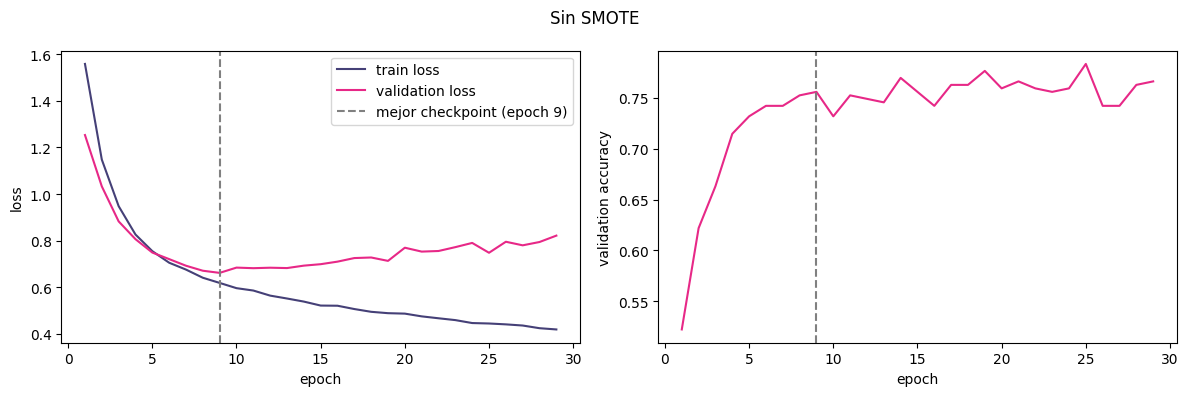

In [26]:
# Experimento 1: entrenamos con el train original
model_base, hist_base, best_base = train_model(loaders["train"], loaders["val"])
plot_history(hist_base, best_base, "Sin SMOTE")

Early stopping en la epoch 30 · mejor epoch: 10
Mejor validation loss: 0.703 (epoch 10)


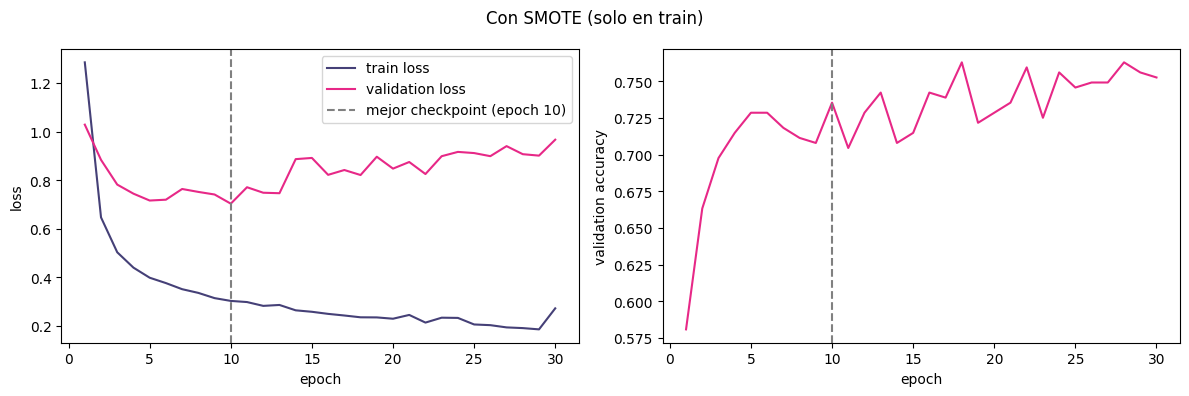

In [27]:
# Experimento 2: mismo modelo y validation, pero entrenando con train aumentado con SMOTE
model_smote, hist_smote, best_smote = train_model(loaders["train_smote"], loaders["val"])
plot_history(hist_smote, best_smote, "Con SMOTE (solo en train)")

**Para comentar:**
- ¿En qué epoch se separan las curvas de train y validation? Ese es el momento en que el modelo empieza
  a memorizar (overfitting), y por eso guardamos el checkpoint anterior.
- Mira el gráfico de la derecha: después del mejor checkpoint la validation **loss** sube, pero la validation **accuracy** puede seguir subiendo un poco. El modelo acierta casi lo mismo, pero con **exceso de confianza** en sus errores, y la loss lo castiga. ¿Qué conviene monitorear para el early stopping: la loss o una métrica como F1?
- Aquí monitoreamos accuracy por simplicidad, pero ya vimos que con clases desbalanceadas no basta.
  En la siguiente sección construimos métricas mejores.

## 9. Evaluación en test con métricas hechas a mano

Recién ahora usamos el test set, una sola vez, para comparar ambos modelos.

Construimos las métricas desde la **confusion matrix** (filas = clase real, columnas = clase predicha):
- **Precision** = TP / (TP + FP) → diagonal dividida por el total de cada **columna**
- **Recall** = TP / (TP + FN) → diagonal dividida por el total de cada **fila**
- **F1** = 2 · P · R / (P + R)

In [28]:
def confusion_matrix_torch(y_true, y_pred, num_classes):
    """Cuenta cada par (real, predicción) con un truco: fila * num_classes + columna.

    Cada par (real, predicción) se convierte en un único número entre 0 y num_classes² - 1.
    bincount cuenta cuántas veces aparece cada número, y reshape lo ordena como matriz
    (filas = clase real, columnas = clase predicción).
    """
    idx = y_true * num_classes + y_pred
    return torch.bincount(idx, minlength=num_classes**2).reshape(num_classes, num_classes)


def per_class_metrics(cm):
    """Precision, recall, F1 y total de cada clase a partir de la confusion matrix."""
    tp = cm.diag().float()  # la diagonal son los aciertos de cada clase
    total_c = cm.sum(dim=1).float()  # total real de cada clase (filas)
    predicted = cm.sum(dim=0).float()  # total predicho de cada clase (columnas)
    zeros = torch.zeros_like(tp)
    # torch.where evita dividir por cero: si una clase nunca se predijo (o no existe), su métrica queda en 0
    precision = torch.where(predicted > 0, tp / predicted, zeros)
    recall = torch.where(total_c > 0, tp / total_c, zeros)
    f1 = torch.where(precision + recall > 0, 2 * precision * recall / (precision + recall), zeros)
    return precision, recall, f1, total_c


def report(cm):
    """Tabla tipo classification_report de sklearn, más la accuracy global."""
    precision, recall, f1, total_c = per_class_metrics(cm)
    table = pd.DataFrame(
        {"precision": precision.numpy(), "recall": recall.numpy(), "f1": f1.numpy(), "total_c": total_c.int().numpy()},
        index=class_names,
    )
    total = total_c.sum()
    # macro avg: promedio simple, todas las clases pesan lo mismo
    table.loc["macro avg"] = [precision.mean().item(), recall.mean().item(), f1.mean().item(), int(total)]
    # weighted avg: promedio ponderado por la cantidad de ejemplos de cada clase (total_c)
    table.loc["weighted avg"] = [
        ((precision * total_c).sum() / total).item(),
        ((recall * total_c).sum() / total).item(),
        ((f1 * total_c).sum() / total).item(),
        int(total),
    ]
    table["total_c"] = table["total_c"].astype(int)
    # accuracy: aciertos (diagonal) sobre el total
    accuracy = (cm.diag().sum() / total).item()
    return table.round(3), accuracy


# Evaluamos ambos modelos en test (recién ahora, una sola vez)
results = {}
for name, model in [("Sin SMOTE", model_base), ("Con SMOTE", model_smote)]:
    y_pred, y_true = predict(model, loaders["test"])
    cm = confusion_matrix_torch(y_true, y_pred, num_classes)
    table, accuracy = report(cm)
    results[name] = {"cm": cm, "table": table, "accuracy": accuracy}
    print(f"===== {name} · accuracy: {accuracy:.3f} =====")
    display(table)

===== Sin SMOTE · accuracy: 0.725 =====


,precision,recall,f1,total_c
Pastry,0.652,0.625,0.638,24
Z_Scratch,0.893,0.893,0.893,28
K_Scratch,0.964,0.898,0.930,59
Stains,0.818,0.818,0.818,11
Dirtiness,0.667,0.750,0.706,8
Bumps,0.610,0.600,0.605,60
Other_Faults,0.632,0.663,0.647,101
macro avg,0.748,0.750,0.748,291
weighted avg,0.730,0.725,0.727,291


===== Con SMOTE · accuracy: 0.722 =====


,precision,recall,f1,total_c
Pastry,0.514,0.792,0.623,24
Z_Scratch,0.926,0.893,0.909,28
K_Scratch,0.915,0.915,0.915,59
Stains,0.625,0.909,0.741,11
Dirtiness,0.571,1.000,0.727,8
Bumps,0.600,0.700,0.646,60
Other_Faults,0.765,0.515,0.615,101
macro avg,0.702,0.818,0.740,291
weighted avg,0.745,0.722,0.719,291


**Cómo leer la confusion matrix**

- Cada **fila** es la clase real y cada **columna** la clase predicha.
- La **diagonal** son los aciertos; todo lo que queda fuera son errores.
- Recorre una fila para ver con qué clases se confunde esa falla: ¿a qué columnas se van sus errores?
- Compara ambas matrices: ¿SMOTE mueve aciertos hacia las clases minoritarias? ¿A costa de qué clase? (Fíjate en `Other_Faults`).

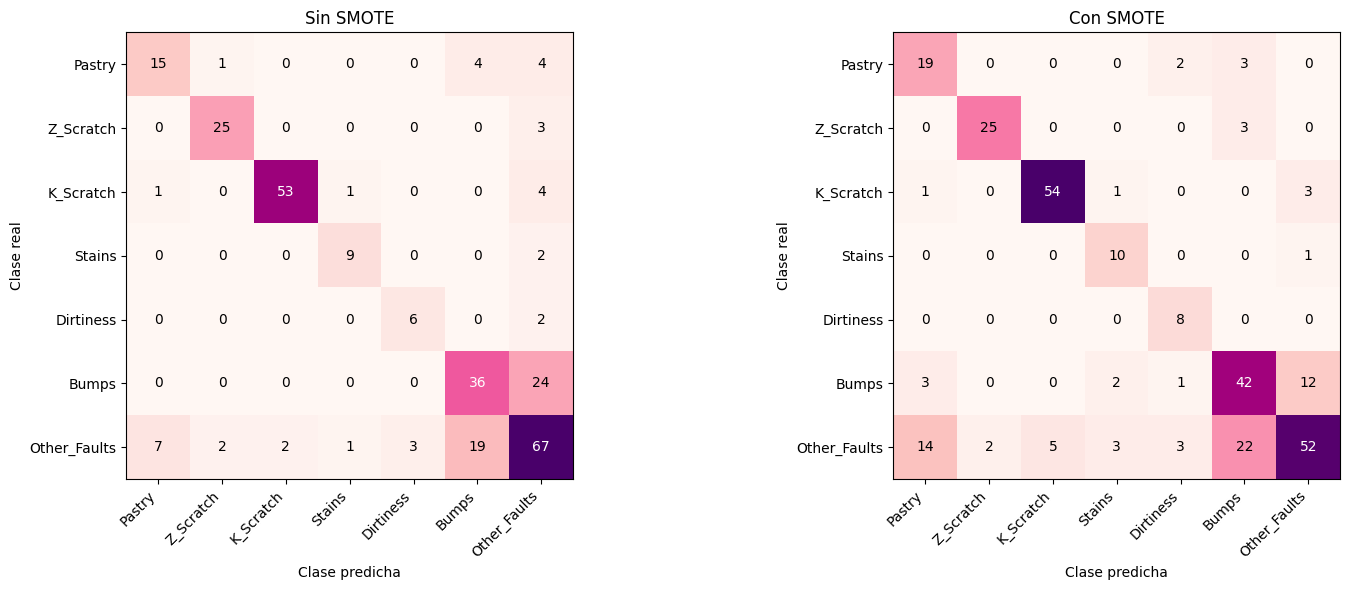

In [29]:
# Confusion matrix de ambos modelos, lado a lado
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
for ax, (name, res) in zip(axes, results.items(), strict=True):
    cm = res["cm"].numpy()
    # imshow dibuja la matriz como imagen: más oscuro = más ejemplos
    ax.imshow(cm, cmap="RdPu")
    # Escribimos el número en cada celda (texto blanco sobre celdas oscuras, negro sobre claras)
    for i in range(num_classes):
        for j in range(num_classes):
            color = "white" if cm[i, j] > cm.max() / 2 else "black"
            ax.text(j, i, int(cm[i, j]), ha="center", va="center", color=color)
    ax.set_xticks(range(num_classes), class_names, rotation=45, ha="right")
    ax.set_yticks(range(num_classes), class_names)
    ax.set_title(name)
    ax.set_xlabel("Clase predicha")
    ax.set_ylabel("Clase real")
plt.tight_layout()
plt.show()

In [30]:
# Resumen comparativo: un diccionario por modelo con sus métricas principales.
# .T transpone la tabla para que cada fila sea un modelo y cada columna una métrica.
summary = pd.DataFrame(
    {
        name: {
            "accuracy": res["accuracy"],
            "F1 macro": res["table"].loc["macro avg", "f1"],
            "F1 weighted": res["table"].loc["weighted avg", "f1"],
            f"recall {class_names[minority]}": res["table"].loc[class_names[minority], "recall"],
        }
        for name, res in results.items()
    }
).T.round(3)
summary

,accuracy,F1 macro,F1 weighted,recall Dirtiness
Sin SMOTE,0.725,0.748,0.727,0.75
Con SMOTE,0.722,0.740,0.719,1.00


In [31]:
# (Opcional) Verificamos que nuestras métricas coinciden con las de scikit-learn
from sklearn.metrics import f1_score

y_pred, y_true = predict(model_smote, loaders["test"])
ours = results["Con SMOTE"]["table"].loc["macro avg", "f1"]
theirs = f1_score(y_true.numpy(), y_pred.numpy(), average="macro")
print(f"F1 macro -> nuestra: {ours:.3f} · sklearn: {theirs:.3f}")

F1 macro -> nuestra: 0.740 · sklearn: 0.740


**Para comentar:**
- ¿Qué clases mejoran su **recall** con SMOTE? ¿Cambia su **precision**?
- ¿Por qué **F1 macro** y **F1 weighted** pueden contar historias distintas con clases desbalanceadas?
- Con un test chico, unos pocos ejemplos cambian bastante las métricas de las clases minoritarias:
  ¿qué tan confiables son esos números?

## 10. Bonus: provocar overfitting

Entrenamos un modelo mucho más grande con pocos datos y **sin early stopping** para ver cómo se
separan las curvas.

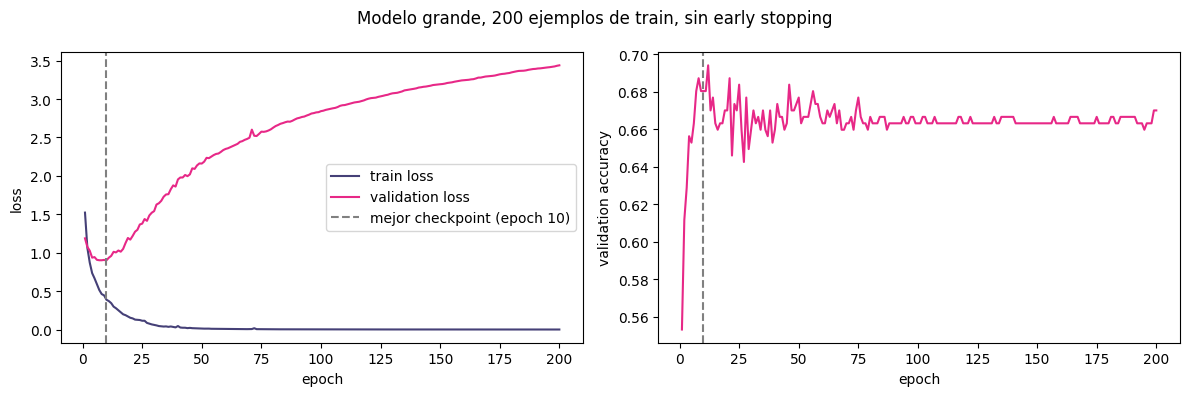

In [32]:
# Tomamos solo 200 ejemplos de train al azar (pocos datos facilitan el overfitting)
small_idx = torch.randperm(len(train_ds), generator=torch.Generator().manual_seed(SEED))[:200]
# Subset crea un "sub-dataset" con solo esos índices, sin copiar los datos
small_loader = DataLoader(Subset(train_ds, small_idx.tolist()), batch_size=32, shuffle=True)

# Modelo mucho más grande (512 neuronas por capa) y patience=10_000: en la práctica, sin early stopping
_, hist_big, best_big = train_model(
    small_loader, loaders["val"], hidden=512, max_epochs=200, patience=10_000, verbose=False
)
plot_history(hist_big, best_big, "Modelo grande, 200 ejemplos de train, sin early stopping")

## 11. Cierre: preguntas para discusión

1. ¿Por qué la normalización ($\mu$, $\sigma$) y SMOTE se calculan **solo** con train?
2. ¿Por qué early stopping guarda el **mejor** checkpoint y no el último?
3. Si fueras jefe de planta, ¿te preocuparía más un **false negative** (una falla que pasa) o un
   **false positive** (una plancha buena descartada)? ¿Qué métrica priorizarías?
4. ¿Qué cambiaría si en vez de SMOTE usáramos *downsampling* de la clase mayoritaria?

---
**Fuente del dataset:** Buscema, M., Terzi, S. y Tastle, W. *Steel Plates Faults*. UCI Machine Learning
Repository (CC BY 4.0). https://archive.ics.uci.edu/dataset/198